In [1]:
import pandas as pd
from pandas_datareader import data as web

#Période d'étude : 8 ans de données
start = "2016-01-01"
end = "2024-01-01"

#Téléchargement depuis FRED
treasury_10y = web.DataReader('DGS10', 'fred', start, end)
sofr = web.DataReader('SOFR', 'fred', start, end)
effr = web.DataReader("EFFR", "fred", start, end)

In [2]:
#Assembler les deux séries en un seul DataFrame
df = pd.concat(
    [
        treasury_10y.rename(columns={'DGS10': 'yield_10Y'}),
        sofr.rename(columns={'SOFR': 'sofr'}),
        effr.rename(columns={"EFFR": "effr"}),
    ],
    axis=1
)

df["financing_rate"] = df["sofr"].fillna(df["effr"])

#Trier par date (au cas où les données ne sont pas dans l'ordre)
df = df.sort_index()

#Vérifier les données manquantes
print('Nombre de valeurs manquantes par colonne: ')
print(df.isna().sum())
print()
print('Premières lignes du DataFrame: ')
print(df.head(10))

Nombre de valeurs manquantes par colonne: 
yield_10Y          87
sofr              651
effr               78
financing_rate     78
dtype: int64

Premières lignes du DataFrame: 
            yield_10Y  sofr  effr  financing_rate
DATE                                             
2016-01-01        NaN   NaN   NaN             NaN
2016-01-04       2.24   NaN  0.36            0.36
2016-01-05       2.25   NaN  0.36            0.36
2016-01-06       2.18   NaN  0.36            0.36
2016-01-07       2.16   NaN  0.36            0.36
2016-01-08       2.13   NaN  0.36            0.36
2016-01-11       2.17   NaN  0.36            0.36
2016-01-12       2.12   NaN  0.36            0.36
2016-01-13       2.08   NaN  0.36            0.36
2016-01-14       2.10   NaN  0.36            0.36


In [3]:
#Afficher la plage de dates et le nombre de lignes
print(f'Période : {df.index.min()} à {df.index.max()}')
print(f'Nombre de jours total : {len(df)}')
print()

#Les données FRED sont en jours ouvrés, on garde uniquement les lignes où au moins une valeur est présente
df = df.dropna(how='all')

#Pour les jours où une seule colonne est manquante, on propage la dernière valeur connue (forward fill)
df = df.ffill()

print("Après nettoyage :")
print(df.isna().sum())
print(df.head(10))


Période : 2016-01-01 00:00:00 à 2024-01-01 00:00:00
Nombre de jours total : 2087

Après nettoyage :
yield_10Y           0
sofr              565
effr                0
financing_rate      0
dtype: int64
            yield_10Y  sofr  effr  financing_rate
DATE                                             
2016-01-04       2.24   NaN  0.36            0.36
2016-01-05       2.25   NaN  0.36            0.36
2016-01-06       2.18   NaN  0.36            0.36
2016-01-07       2.16   NaN  0.36            0.36
2016-01-08       2.13   NaN  0.36            0.36
2016-01-11       2.17   NaN  0.36            0.36
2016-01-12       2.12   NaN  0.36            0.36
2016-01-13       2.08   NaN  0.36            0.36
2016-01-14       2.10   NaN  0.36            0.36
2016-01-15       2.03   NaN  0.36            0.36


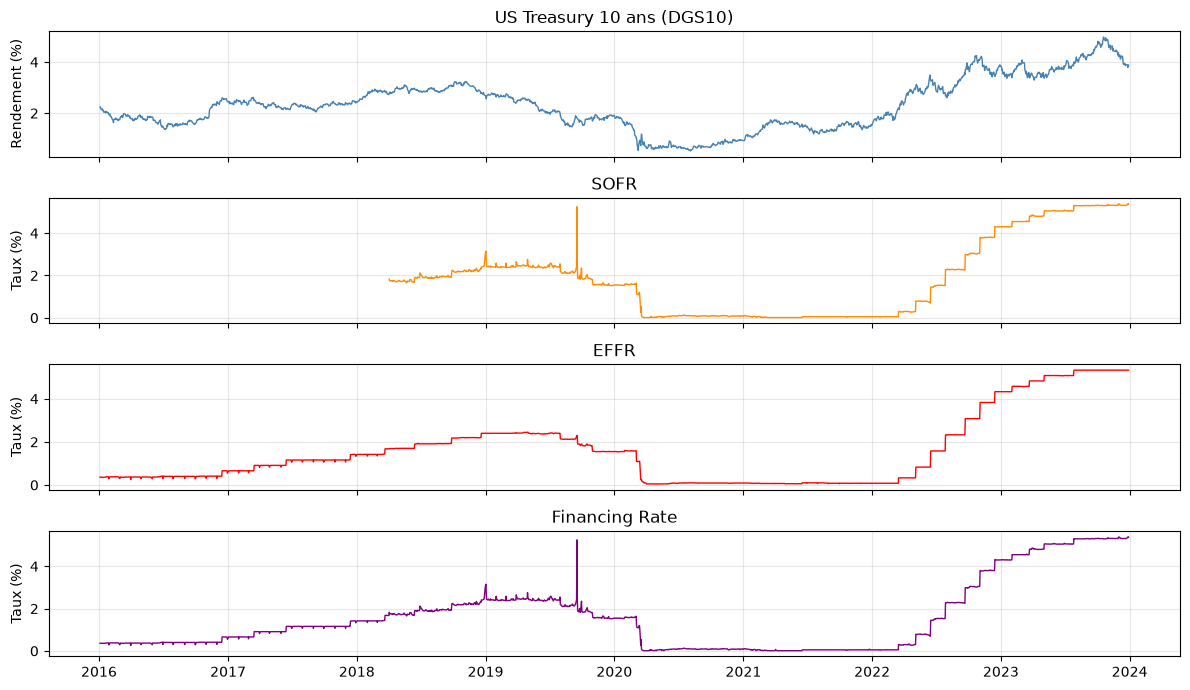

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 7), sharex=True)

ax1.plot(df.index, df["yield_10Y"], color="steelblue", linewidth=1)
ax1.set_ylabel("Rendement (%)")
ax1.set_title("US Treasury 10 ans (DGS10)")
ax1.grid(True, alpha=0.3)

ax2.plot(df.index, df["sofr"], color="darkorange", linewidth=1)
ax2.set_ylabel("Taux (%)")
ax2.set_title("SOFR")
ax2.grid(True, alpha=0.3)

ax3.plot(df.index, df["effr"], color="red", linewidth=1)
ax3.set_ylabel("Taux (%)")
ax3.set_title("EFFR")
ax3.grid(True, alpha=0.3)

ax4.plot(df.index, df["financing_rate"], color="purple", linewidth=1)
ax4.set_ylabel("Taux (%)")
ax4.set_title("Financing Rate")
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
df.to_csv('C:\\Users\\chris\\OneDrive\\Bureau\\Projets\\treasury-basis-trading\\data\\processed\\treasury_rates.csv')
print('Données sauvegardées.')

Données sauvegardées.
